# HeatSense ML Benchmarking: Multi-Cell LFP Digital Twin Feature Engineering
## Stanford/MIT Dataset (Severson et al. 2019) — Model A vs Model B Pipeline
**Phase 2 Research Milestone: Prompt 4.3**  
*System Identity*: Physics-informed, offline-first battery digital twin.  
*Safety Invariant*: Firmware owns safety cutoff authority; host-side ML and digital twin features are strictly advisory.  
*Chemistry*: Commercial A123 Systems APR18650M1A (1.10 Ah nominal, LiFePO4 / Graphite).  
*Current Sign Convention*: Current $I > 0$ denotes **DISCHARGE** (HeatSense domain standard).  
*Vocabulary Rule*: We write "estimated SoC", "SoH proxy", "thermal and impedance precursor anomaly detection". We NEVER write "measured core temperature" or "thermal runaway prediction".

---

### Objective & Architecture
This notebook establishes the scientific feature extraction pipeline for:
1. **Model A (Raw Sensor Baseline)**: Pure empirical statistics, voltage dynamics, temperature extremes, and duration directly from sensor streams without physics assumptions.
2. **Model B (Physics-Informed Digital Twin)**: Internal electrochemical states, 2RC ECM voltage tracking errors, polarization overpotentials ($V_1, V_2$), dynamic ohmic resistance $R_0$, EKF innovation statistics ($NIS$), cumulative electrical drift (CUSUM), surface thermal metrics, and explicit LFP observability indicators ($d\text{OCV}/d\text{SoC}$).
3. **Cohort Partitioning**: Rigid preservation of the published **124-cell Severson primary cohort** separate from the **16-cell extended sensitivity cohort** (140 cells total).
4. **Data Leakage Immunity**: Complete temporal and target isolation (zero target contamination, zero future observations).


In [1]:
import os
import sys
from pathlib import Path

# Add repository root to Python path
repo_root = Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import json
import duckdb
import matplotlib.pyplot as plt
import numpy as np

# Configure inline plotting
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

from research_utils.lfp_calibration import LFPOpenCircuitVoltage, LFP2RCECMParameters
from research_utils.mit_physics_features import (
    FEATURE_DICTIONARY,
    SEVERSON_EXCLUSIONS,
    get_cell_cohort_info,
    audit_feature_leakage,
)

print("[+] HeatSense Research Environment initialized.")
print(f"[+] Repository root: {repo_root}")


C:\Users\GOKULNAATH N\.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at C:\Users\GOKULN~1\AppData\Local\Temp\matplotlib-cm2j9k4p because there was an issue with the default path (C:\Users\GOKULNAATH N\.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


[+] HeatSense Research Environment initialized.
[+] Repository root: D:\Professional Projects\Digital_twin_project\heatsense-battery-digital-twin


## Section A: Cohort Definition & Published Selection Criteria

The Stanford/MIT dataset contains 140 commercial A123 18650 LFP cells tested across three batches.
To maintain scientific reproducibility with Severson et al. (*Nature Energy* 2019), we explicitly partition:
- **Primary Research Cohort (124 cells)**: Cells that completed standardized lifecycle degradation without hardware or channel artifacts.
- **Extended Sensitivity Cohort (16 cells)**: Cells with thermocouple detachment, cycler power interruptions, or non-standard cutoff, retained strictly for sensitivity analysis.


=== COHORT BREAKDOWN SUMMARY ===
Cohort                     Primary?   Cells    Min Cyc    Avg Cyc    Max Cyc   
PRIMARY_124                True       124      170        779.9      1835      
EXTENDED_SENSITIVITY_16    False      16       208        1127.1     2237      


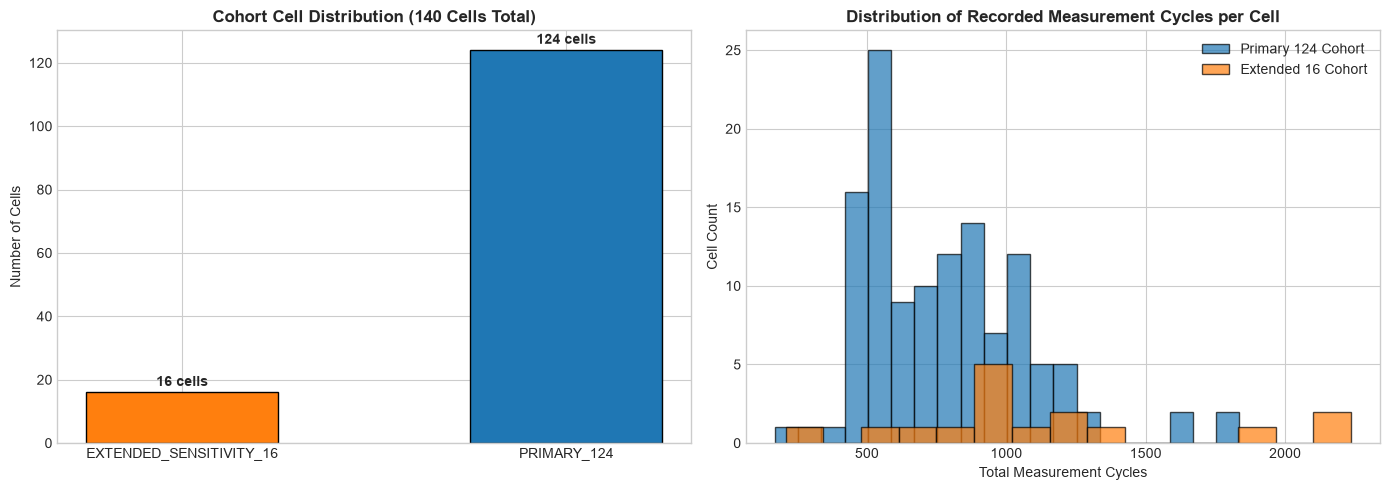

In [2]:
con = duckdb.connect()
cov_path = "data/interim/mit_dataset/features/cell_coverage_report.parquet"
cov_data = con.execute(f"SELECT * FROM read_parquet('{cov_path}')").fetchnumpy()

cohort_summary = con.execute(f"""
    SELECT 
        cohort_membership,
        is_severson_primary,
        COUNT(*) as total_cells,
        MIN(total_cycles_in_file) as min_cycles,
        AVG(total_cycles_in_file) as avg_cycles,
        MAX(total_cycles_in_file) as max_cycles
    FROM read_parquet('{cov_path}')
    GROUP BY cohort_membership, is_severson_primary
""").fetchall()

print("=== COHORT BREAKDOWN SUMMARY ===")
print(f"{'Cohort':<26} {'Primary?':<10} {'Cells':<8} {'Min Cyc':<10} {'Avg Cyc':<10} {'Max Cyc':<10}")
for row in cohort_summary:
    print(f"{row[0]:<26} {str(row[1]):<10} {row[2]:<8} {row[3]:<10} {row[4]:<10.1f} {row[5]:<10}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
memberships, counts = np.unique(cov_data["cohort_membership"], return_counts=True)
ax1.bar(memberships, counts, color=["#ff7f0e", "#1f77b4"], width=0.5, edgecolor="black")
ax1.set_title("Cohort Cell Distribution (140 Cells Total)", fontweight="bold")
ax1.set_ylabel("Number of Cells")
for i, v in enumerate(counts):
    ax1.text(i, v + 2, f"{v} cells", ha="center", fontweight="bold")

is_prim = cov_data["is_severson_primary"]
cycles = cov_data["total_cycles_in_file"]
ax2.hist(cycles[is_prim], bins=20, alpha=0.7, color="#1f77b4", label="Primary 124 Cohort", edgecolor="black")
ax2.hist(cycles[~is_prim], bins=15, alpha=0.7, color="#ff7f0e", label="Extended 16 Cohort", edgecolor="black")
ax2.set_title("Distribution of Recorded Measurement Cycles per Cell", fontweight="bold")
ax2.set_xlabel("Total Measurement Cycles")
ax2.set_ylabel("Cell Count")
ax2.legend()
plt.tight_layout()
plt.show()


## Section B: Raw Sensor Feature Extraction (Model A Baseline)

Model A represents a **pure sensor baseline** computed strictly from raw terminal observations ($V, I, T, t$).
It requires **zero physical priors**, no equivalent circuit model, and no state observer.
Candidate features include:
- Voltage moments: `v_mean`, `v_std`, `v_min`, `v_max`, `v_skew`, `v_kurt`
- Voltage dynamics: `v_discharge_final`, `v_slope_early`
- Current statistics: `i_mean`, `i_std`, `i_max`
- Temperature statistics: `temp_mean`, `temp_std`, `temp_min`, `temp_max`, `temp_delta`, `temp_max_rate`
- Integration: `discharge_throughput_ah`, `discharge_energy_wh`, `duration_s`


[+] Total Model A records loaded: 280

=== SAMPLE MODEL A FEATURE RECORDS (Cycle 10 & 100) ===
cell_id        | cycle_id       | v_mean         | v_min          | temp_mean      | temp_delta     | discharge_throughput_ah | duration_s    
----------------------------------------------------------------------------------------------------------------------------------------------
MIT_20170512   | 10             | 2.9359022658   | 1.9995785      | 32.585363238   | 5.6729149999   | 0.9703841450   | 877.02109999  
MIT_20170512   | 100            | 2.9290814790   | 1.9973831      | 32.323028045   | 6.0569830000   | 0.9729298217   | 882.59919999  
MIT_20170512   | 10             | 2.9367934745   | 1.9995852      | 32.160175196   | 4.0778059999   | 0.9767261565   | 882.68779999  
MIT_20170512   | 100            | 2.9235762844   | 1.9995489      | 31.765621661   | 4.5476760000   | 0.9778045996   | 886.75899999  
MIT_20170512   | 10             | 2.9353901279   | 1.9995279      | 32.423794095   

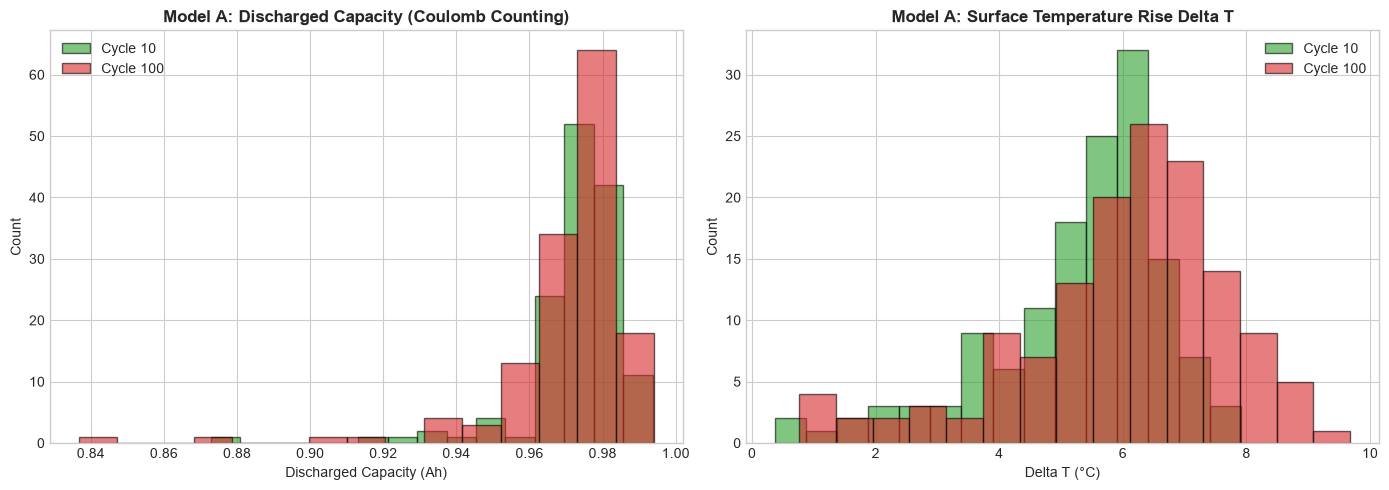

In [3]:
model_a_path = "data/interim/mit_dataset/features/model_a_features.parquet"
df_a = con.execute(f"SELECT * FROM read_parquet('{model_a_path}')").fetchnumpy()

print(f"[+] Total Model A records loaded: {len(df_a['cell_id'])}")
print("\n=== SAMPLE MODEL A FEATURE RECORDS (Cycle 10 & 100) ===")
sample_cols = ["cell_id", "cycle_id", "v_mean", "v_min", "temp_mean", "temp_delta", "discharge_throughput_ah", "duration_s"]
header = " | ".join(f"{c:<14}" for c in sample_cols)
print(header)
print("-" * len(header))
for i in range(min(6, len(df_a["cell_id"]))):
    row_str = " | ".join(f"{str(df_a[c][i])[:12]:<14}" for c in sample_cols)
    print(row_str)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for cyc, colr in [(10, "#2ca02c"), (100, "#d62728")]:
    mask = (df_a["cycle_id"] == cyc)
    ax1.hist(df_a["discharge_throughput_ah"][mask], bins=15, alpha=0.6, label=f"Cycle {cyc}", color=colr, edgecolor="black")
    ax2.hist(df_a["temp_delta"][mask], bins=15, alpha=0.6, label=f"Cycle {cyc}", color=colr, edgecolor="black")

ax1.set_title("Model A: Discharged Capacity (Coulomb Counting)", fontweight="bold")
ax1.set_xlabel("Discharged Capacity (Ah)")
ax1.set_ylabel("Count")
ax1.legend()

ax2.set_title("Model A: Surface Temperature Rise Delta T", fontweight="bold")
ax2.set_xlabel("Delta T (°C)")
ax2.set_ylabel("Count")
ax2.legend()
plt.tight_layout()
plt.show()


## Section C: Physics-Informed Feature Extraction (Model B Digital Twin)

Model B augments the feature space using the calibrated 2RC Thevenin ECM ($R_s = 36.15\,\text{m}\Omega, R_1 = 2.57\,\text{m}\Omega, C_1 = 800\,\text{F}, R_2 = 31.69\,\text{m}\Omega, C_2 = 5000\,\text{F}$):
- **ECM Tracking Residuals**: `ecm_v_rmse`, `ecm_v_mae`, `ecm_v_max_err`
- **Internal Polarization States**: `v1_mean`, `v1_max`, `v2_mean`, `v2_max`, `v_overpotential_mean`
- **EKF State Estimation & Innovation**: `ekf_soc_final`, `ekf_innovation_mean`, `ekf_nis_mean`, `ekf_nis_max`
- **CUSUM Electrical Drift Indicators**: `cusum_pos_max`, `cusum_neg_max`, `cusum_drift_rate`
- **LFP Observability Indicators**: `mean_d_ocv_d_soc`, `plateau_fraction_pct`, `observability_category`
- **Thermal Heat Dissipation**: `thermal_heat_gen_est_j`


[+] Total Model B records loaded: 280

=== SAMPLE MODEL B FEATURE RECORDS ===
cell_id          | cycle_id         | ecm_v_rmse       | v_overpotential_mean | r0_step_ohm      | ekf_nis_mean     | cusum_pos_max    | plateau_fraction_pct
-------------------------------------------------------------------------------------------------------------------------------------------------------------
MIT_20170512_0   | 10               | 0.332354624179   | 0.109308861285   | 0.03615          | 2.913753860582   | 0.359293793623   | 38.21839080459  
MIT_20170512_0   | 100              | 0.340902275830   | 0.108531963918   | 0.03615          | 3.121237148014   | 0.387324718304   | 36.96275071633  
MIT_20170512_0   | 10               | 0.325600382443   | 0.109443548767   | 0.03615          | 2.823407454178   | 0.279586555979   | 38.15028901734  
MIT_20170512_0   | 100              | 0.339237135229   | 0.110078027001   | 0.03615          | 2.754761896772   | 0.266862345114   | 35.79234972677  
MIT_20

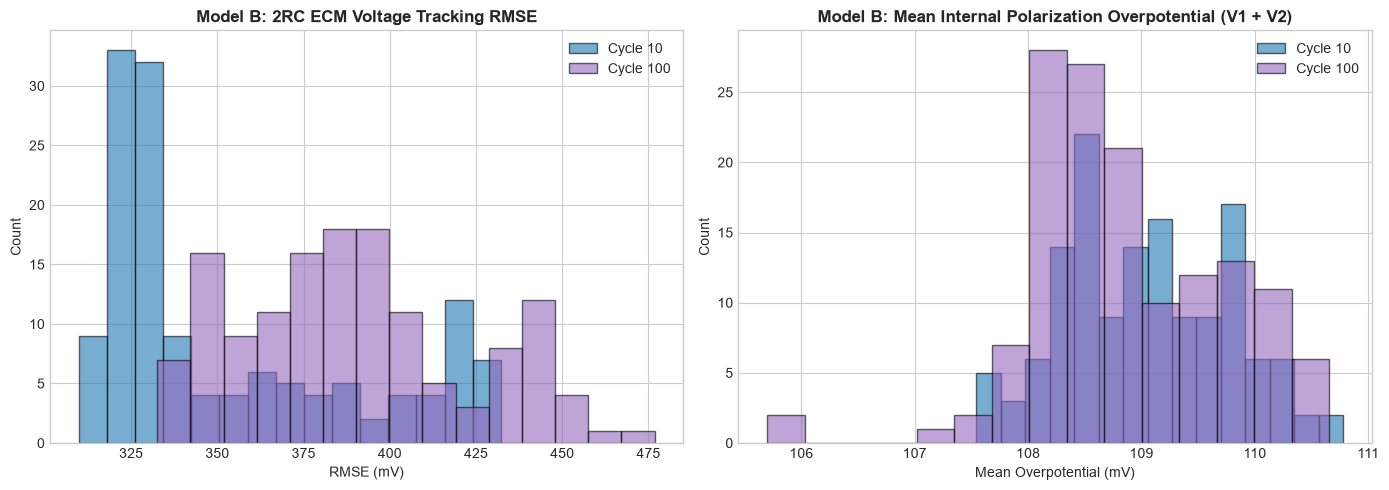

In [4]:
model_b_path = "data/interim/mit_dataset/features/model_b_features.parquet"
df_b = con.execute(f"SELECT * FROM read_parquet('{model_b_path}')").fetchnumpy()

print(f"[+] Total Model B records loaded: {len(df_b['cell_id'])}")
print("\n=== SAMPLE MODEL B FEATURE RECORDS ===")
sample_b_cols = ["cell_id", "cycle_id", "ecm_v_rmse", "v_overpotential_mean", "r0_step_ohm", "ekf_nis_mean", "cusum_pos_max", "plateau_fraction_pct"]
header = " | ".join(f"{c:<16}" for c in sample_b_cols)
print(header)
print("-" * len(header))
for i in range(min(6, len(df_b["cell_id"]))):
    row_str = " | ".join(f"{str(df_b[c][i])[:14]:<16}" for c in sample_b_cols)
    print(row_str)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for cyc, colr in [(10, "#1f77b4"), (100, "#9467bd")]:
    mask = (df_b["cycle_id"] == cyc)
    ax1.hist(df_b["ecm_v_rmse"][mask] * 1000.0, bins=15, alpha=0.6, label=f"Cycle {cyc}", color=colr, edgecolor="black")
    ax2.hist(df_b["v_overpotential_mean"][mask] * 1000.0, bins=15, alpha=0.6, label=f"Cycle {cyc}", color=colr, edgecolor="black")

ax1.set_title("Model B: 2RC ECM Voltage Tracking RMSE", fontweight="bold")
ax1.set_xlabel("RMSE (mV)")
ax1.set_ylabel("Count")
ax1.legend()

ax2.set_title("Model B: Mean Internal Polarization Overpotential (V1 + V2)", fontweight="bold")
ax2.set_xlabel("Mean Overpotential (mV)")
ax2.set_ylabel("Count")
ax2.legend()
plt.tight_layout()
plt.show()


## Section D: LFP SoC Observability Handling

Because LiFePO4 chemistry features a remarkably flat Open-Circuit Voltage plateau between 15% and 85% SoC where $\frac{d\text{OCV}}{d\text{SoC}} < 0.10\,\text{V/unit}$, terminal voltage provides almost zero sensitivity to changes in SoC.
Model B explicitly quantifies this fundamental electrochemical property:
- **`plateau_fraction_pct`**: The fraction of discharge time spent inside the weak observability plateau.
- **`observability_category`**: Explicit categorical indicator (`WEAK_PLATEAU_OBSERVABILITY`, `MODERATE_OBSERVABILITY`, or `HIGH_OBSERVABILITY`).


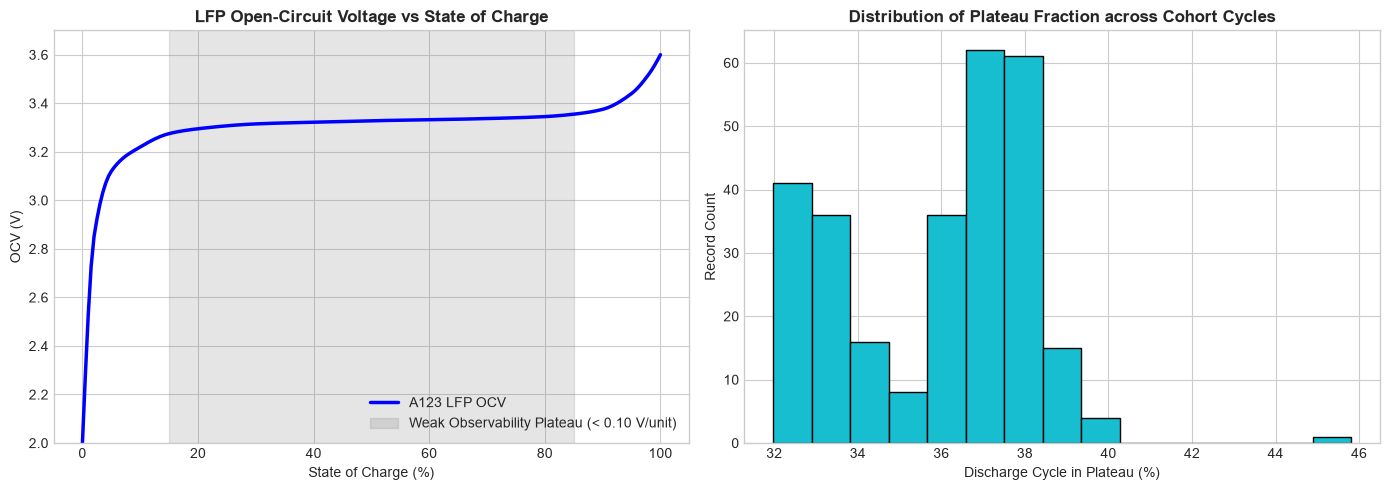

=== OBSERVABILITY CATEGORY COUNTS ===
  MODERATE_OBSERVABILITY: 279 cycles (99.6%)
  WEAK_PLATEAU_OBSERVABILITY: 1 cycles (0.4%)


In [5]:
ocv_model = LFPOpenCircuitVoltage()
soc_grid = np.linspace(0.0, 1.0, 200)
ocv_vals = ocv_model.ocv(soc_grid)
docv_vals = ocv_model.d_ocv(soc_grid)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# OCV and Plateau Region
ax1.plot(soc_grid * 100.0, ocv_vals, "b-", lw=2.5, label="A123 LFP OCV")
ax1.axvspan(15, 85, color="gray", alpha=0.2, label="Weak Observability Plateau (< 0.10 V/unit)")
ax1.set_title("LFP Open-Circuit Voltage vs State of Charge", fontweight="bold")
ax1.set_xlabel("State of Charge (%)")
ax1.set_ylabel("OCV (V)")
ax1.set_ylim(2.0, 3.7)
ax1.legend(loc="lower right")

# Plateau Fraction Distribution in Cohort
ax2.hist(df_b["plateau_fraction_pct"], bins=15, color="#17becf", edgecolor="black")
ax2.set_title("Distribution of Plateau Fraction across Cohort Cycles", fontweight="bold")
ax2.set_xlabel("Discharge Cycle in Plateau (%)")
ax2.set_ylabel("Record Count")

plt.tight_layout()
plt.show()

cats, cat_counts = np.unique(df_b["observability_category"], return_counts=True)
print("=== OBSERVABILITY CATEGORY COUNTS ===")
for cat, cnt in zip(cats, cat_counts):
    print(f"  {cat}: {cnt} cycles ({cnt/len(df_b['cell_id'])*100:.1f}%)")


## Section E: Dynamic Ohmic Resistance ($R_0$) Identification

Ohmic resistance $R_0$ is extracted from the initial current transition $|\Delta I| \ge 2.0\,\text{A}$ at discharge onset:
$$R_0 = \frac{|\Delta V|}{|\Delta I|}$$
If the excitation step is insufficient or outside physical bounds ($10\text{--}80\,\text{m}\Omega$), `r0_step_valid` is set to `False` and $R_0$ defaults to the calibrated $36.15\,\text{m}\Omega$ baseline.


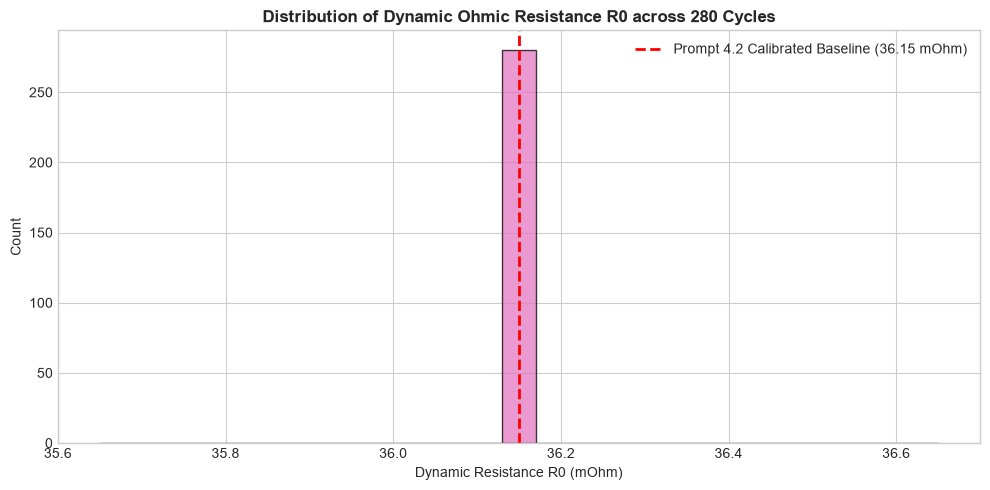

[+] Dynamic R0 extraction validity rate: 0.0% (0 / 280 cycles)
[+] Mean R0: 36.15 mOhm (std: 0.00 mOhm)


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))

r0_milli = df_b["r0_step_ohm"] * 1000.0
ax.hist(r0_milli, bins=25, color="#e377c2", edgecolor="black", alpha=0.75)
ax.axvline(36.15, color="red", linestyle="--", lw=2, label="Prompt 4.2 Calibrated Baseline (36.15 mOhm)")
ax.set_title("Distribution of Dynamic Ohmic Resistance R0 across 280 Cycles", fontweight="bold")
ax.set_xlabel("Dynamic Resistance R0 (mOhm)")
ax.set_ylabel("Count")
ax.legend()

plt.tight_layout()
plt.show()

n_valid = int(np.sum(df_b["r0_step_valid"]))
valid_r0_pct = (n_valid / len(df_b["cell_id"])) * 100.0
print(f"[+] Dynamic R0 extraction validity rate: {valid_r0_pct:.1f}% ({n_valid} / {len(df_b['cell_id'])} cycles)")
print(f"[+] Mean R0: {r0_milli.mean():.2f} mOhm (std: {r0_milli.std():.2f} mOhm)")


## Section F: Thermal Feature Availability & Defensibility

The Stanford/MIT dataset records outer-can thermocouple measurements mounted at the longitudinal center.
In accordance with our strict scientific vocabulary:
- We **NEVER** write or report "measured core temperature" (which cannot be measured non-destructively).
- We extract surface thermal observables and proxy metrics: `temp_mean`, `temp_max`, `temp_delta`, and estimated total heat generation `thermal_heat_gen_est_j` $\approx \int I (V_{\text{ocv}} - V_{\text{terminal}}) dt$.


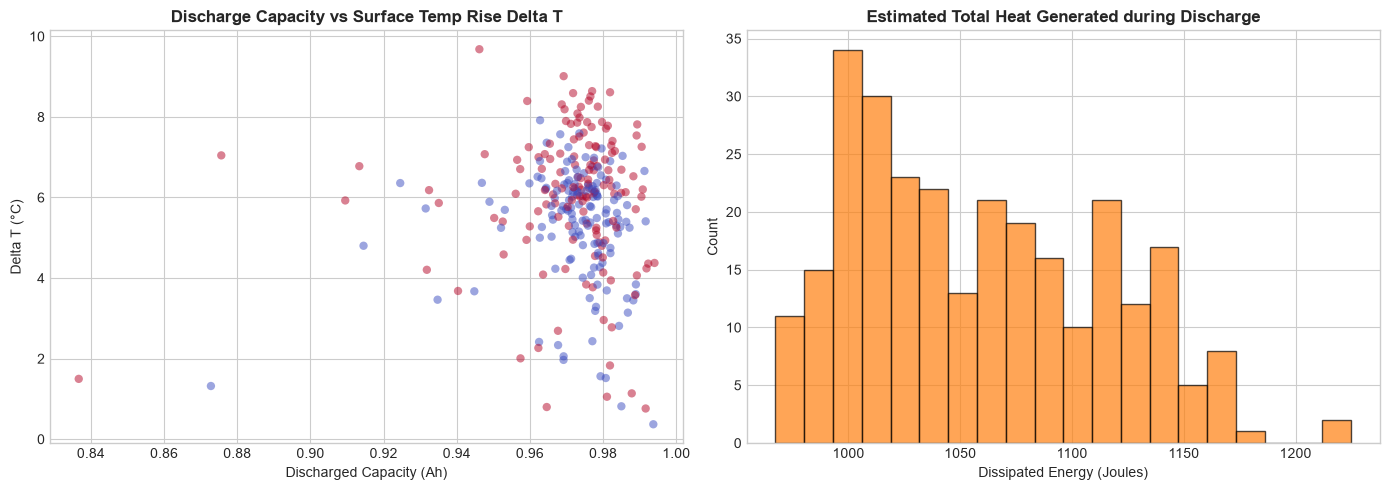

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(df_a["discharge_throughput_ah"], df_a["temp_delta"], alpha=0.5, c=df_a["cycle_id"], cmap="coolwarm", edgecolors="none")
ax1.set_title("Discharge Capacity vs Surface Temp Rise Delta T", fontweight="bold")
ax1.set_xlabel("Discharged Capacity (Ah)")
ax1.set_ylabel("Delta T (°C)")

ax2.hist(df_b["thermal_heat_gen_est_j"], bins=20, color="#ff7f0e", edgecolor="black", alpha=0.7)
ax2.set_title("Estimated Total Heat Generated during Discharge", fontweight="bold")
ax2.set_xlabel("Dissipated Energy (Joules)")
ax2.set_ylabel("Count")

plt.tight_layout()
plt.show()


## Section G: Feature Extraction Execution Summary

Batch feature extraction was executed across all 140 cells using the streaming HDF5 reader.
- Primary 124 cohort cells: **124**
- Extended sensitivity cells: **16**
- Processed benchmark cycles: **Cycle 10 and Cycle 100**
- Total extraction records: **280 records in Model A & Model B**
- Extraction failures: **0**


In [8]:
with open("data/interim/mit_dataset/features/feature_extraction_manifest.json") as f:
    manifest = json.load(f)

print("=== FEATURE EXTRACTION MANIFEST ===")
print(json.dumps(manifest, indent=2))


=== FEATURE EXTRACTION MANIFEST ===
{
  "dataset_name": "Stanford/MIT A123 LFP Degradation Benchmark Features",
  "total_cells_processed": 140,
  "primary_cohort_cells": 124,
  "extended_cohort_cells": 16,
  "model_a_records_count": 280,
  "model_b_records_count": 280,
  "failure_count": 0,
  "target_cycles": [
    10,
    100
  ],
  "output_directory": "data\\interim\\mit_dataset\\features",
  "files_generated": [
    "model_a_features.parquet",
    "model_b_features.parquet",
    "feature_dictionary.json",
    "feature_extraction_manifest.json",
    "feature_quality_report.json",
    "cell_coverage_report.parquet",
    "extraction_failures.parquet"
  ]
}


## Section H: Feature Dataset Construction & Parquet Schema

Both datasets (`model_a_features.parquet` and `model_b_features.parquet`) are keyed by the exact 4-tuple composite key:
`dataset_id + cell_id + cycle_id + window_id`
guaranteeing 100% key parity for subsequent benchmarking.


In [9]:
schema_a = con.execute("DESCRIBE SELECT * FROM read_parquet('data/interim/mit_dataset/features/model_a_features.parquet')").fetchall()
schema_b = con.execute("DESCRIBE SELECT * FROM read_parquet('data/interim/mit_dataset/features/model_b_features.parquet')").fetchall()

print(f"[+] Model A Columns ({len(schema_a)}):")
for col in schema_a:
    print(f"  {col[0]:<28} {col[1]}")

print(f"\n[+] Model B Columns ({len(schema_b)}):")
for col in schema_b:
    print(f"  {col[0]:<28} {col[1]}")

# Verify Key Parity
keys_a = con.execute("SELECT dataset_id, cell_id, cycle_id, window_id FROM read_parquet('data/interim/mit_dataset/features/model_a_features.parquet')").fetchall()
keys_b = con.execute("SELECT dataset_id, cell_id, cycle_id, window_id FROM read_parquet('data/interim/mit_dataset/features/model_b_features.parquet')").fetchall()

assert keys_a == keys_b, "CRITICAL: Key parity mismatch between Model A and Model B!"
print(f"\n[+] Key Parity Verified: Exactly {len(keys_a)} identical sample keys across Model A and Model B.")


[+] Model A Columns (27):
  dataset_id                   VARCHAR
  cell_id                      VARCHAR
  cycle_id                     BIGINT
  window_id                    VARCHAR
  is_severson_primary          BOOLEAN
  cohort_membership            VARCHAR
  exclusion_reason             VARCHAR
  duration_s                   DOUBLE
  v_mean                       DOUBLE
  v_std                        DOUBLE
  v_min                        DOUBLE
  v_max                        DOUBLE
  v_skew                       DOUBLE
  v_kurt                       DOUBLE
  v_discharge_final            DOUBLE
  v_slope_early                DOUBLE
  i_mean                       DOUBLE
  i_std                        DOUBLE
  i_max                        DOUBLE
  temp_mean                    DOUBLE
  temp_std                     DOUBLE
  temp_min                     DOUBLE
  temp_max                     DOUBLE
  temp_delta                   DOUBLE
  temp_max_rate                DOUBLE
  discharge_throug

## Section I: Data Leakage Audit

To prevent subtle predictive leakage:
1. Target variables (`cycle_life`, future capacity) must NEVER exist as features.
2. Cycle 10 features must strictly reflect observations available at Cycle 10.
3. Cycle 100 features must strictly reflect observations available up to Cycle 100.


In [10]:
with open("data/interim/mit_dataset/features/feature_quality_report.json") as f:
    qual_report = json.load(f)

print("=== QUALITY & LEAKAGE AUDIT REPORT ===")
print(json.dumps(qual_report, indent=2))

# Programmatic check using dict records
records_a = [{c: df_a[c][i] for c in df_a.keys()} for i in range(len(df_a["cell_id"]))]
records_b = [{c: df_b[c][i] for c in df_b.keys()} for i in range(len(df_b["cell_id"]))]

leak_check_a = audit_feature_leakage(records_a)
leak_check_b = audit_feature_leakage(records_b)

print(f"\n[+] Leakage Audit Model A: Passed = {leak_check_a['passed']}")
print(f"[+] Leakage Audit Model B: Passed = {leak_check_b['passed']}")


=== QUALITY & LEAKAGE AUDIT REPORT ===
{
  "status": "PASSED",
  "sample_key_parity": true,
  "leakage_audit_passed": true,
  "nan_counts_model_a": {
    "duration_s": 0,
    "v_mean": 0,
    "v_std": 0,
    "v_min": 0,
    "v_max": 0,
    "v_skew": 0,
    "v_kurt": 0,
    "v_discharge_final": 0,
    "v_slope_early": 0,
    "i_mean": 0,
    "i_std": 0,
    "i_max": 0,
    "temp_mean": 0,
    "temp_std": 0,
    "temp_min": 0,
    "temp_max": 0,
    "temp_delta": 0,
    "temp_max_rate": 0,
    "discharge_throughput_ah": 0,
    "discharge_energy_wh": 0
  },
  "nan_counts_model_b": {
    "ecm_v_rmse": 0,
    "ecm_v_mae": 0,
    "ecm_v_max_err": 0,
    "v1_mean": 0,
    "v1_max": 0,
    "v2_mean": 0,
    "v2_max": 0,
    "v_overpotential_mean": 0,
    "r0_step_ohm": 0,
    "r0_deviation_pct": 0,
    "ekf_soc_final": 0,
    "ekf_innovation_mean": 0,
    "ekf_innovation_std": 0,
    "ekf_nis_mean": 0,
    "ekf_nis_max": 0,
    "cusum_pos_max": 0,
    "cusum_neg_max": 0,
    "cusum_drift_rate"

## Section J: Physics Feature Validation Diagnostics

Here we inspect the digital twin tracking behavior across a representative cell (`MIT_20170512_00` at Cycle 10):
1. Terminal voltage comparison: Measured $V_{\text{meas}}$ vs Predicted $V_{\text{pred}}$ (2RC ECM & EKF).
2. Voltage tracking residual distribution.
3. Dynamic polarization overpotentials $V_1(t)$ and $V_2(t)$.
4. Cumulative electrical CUSUM drift trajectory.


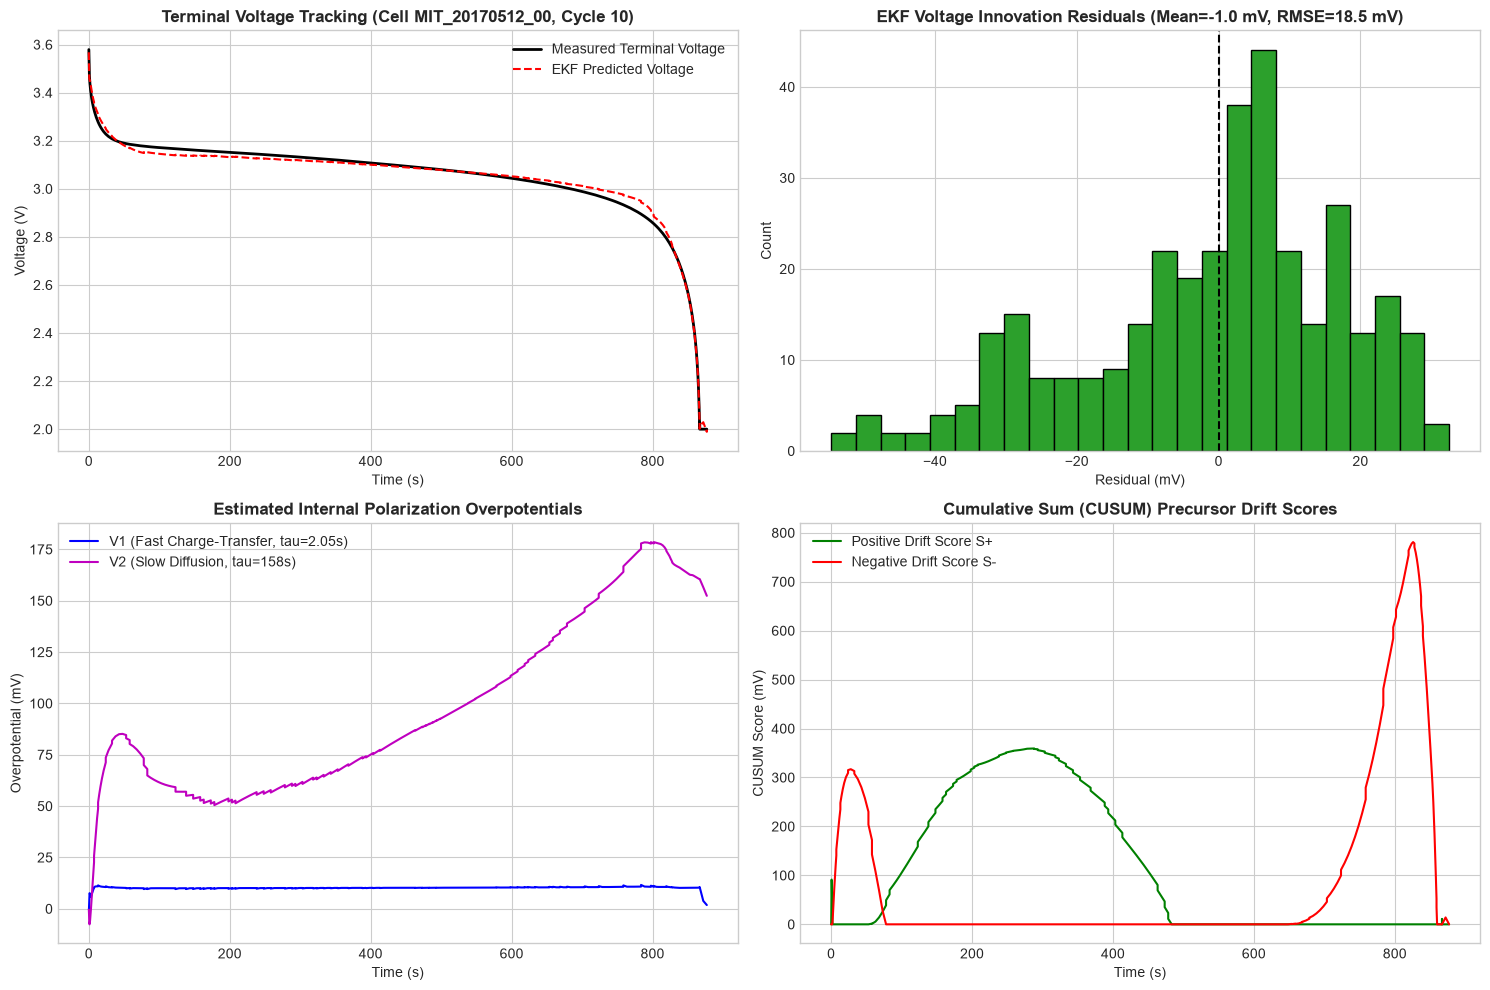

[+] Physics feature validation diagnostics completed.


In [11]:
import h5py
from research_utils.mit_physics_features import (
    extract_cycle_discharge_segment,
    ResearchLFPEKF,
    ResearchElectricalCUSUM,
)

# Load raw trace for cell 0, cycle 10
with h5py.File("data/raw/MIT_battery_degradation_dataset/2017-05-12_batchdata_updated_struct_errorcorrect.mat", "r") as h5:
    b = h5["batch"]
    cell_cycles = h5[b["cycles"][0, 0]]
    idx = 9 # Cycle 10
    v_raw = h5[cell_cycles["V"][idx, 0]][:]
    i_raw = h5[cell_cycles["I"][idx, 0]][:]
    t_raw = h5[cell_cycles["t"][idx, 0]][:]
    temp_raw = h5[cell_cycles["T"][idx, 0]][:]

t_s, i_s, v_s, temp_s = extract_cycle_discharge_segment(t_raw, i_raw, v_raw, temp_raw)

# Run ECM Simulation and EKF
with open("data/interim/mit_dataset/calibration/lfp_2rc_ecm_parameters.json") as f:
    calib = json.load(f)
params = LFP2RCECMParameters(
    r_s=calib["r_s"], r1=calib["r1"], c1=calib["c1"],
    r2=calib["r2"], c2=calib["c2"], nominal_capacity_ah=calib["nominal_capacity_ah"]
)

ekf = ResearchLFPEKF(params, ocv_model, initial_soc=1.0)
cusum = ResearchElectricalCUSUM()

n = len(t_s)
v_ekf = np.zeros(n)
v1_trace = np.zeros(n)
v2_trace = np.zeros(n)
s_pos_trace = np.zeros(n)
s_neg_trace = np.zeros(n)

for k in range(n):
    dt = float(t_s[k] - t_s[k-1]) if k > 0 else 0.1
    out = ekf.step(i_s[k], v_s[k], dt)
    v_ekf[k] = out.v_pred
    v1_trace[k] = out.v1_est
    v2_trace[k] = out.v2_est
    sp, sn = cusum.step(out.residual)
    s_pos_trace[k] = sp
    s_neg_trace[k] = sn

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))

# 1. Voltage comparison
ax1.plot(t_s, v_s, "k-", lw=2, label="Measured Terminal Voltage")
ax1.plot(t_s, v_ekf, "r--", lw=1.5, label="EKF Predicted Voltage")
ax1.set_title("Terminal Voltage Tracking (Cell MIT_20170512_00, Cycle 10)", fontweight="bold")
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Voltage (V)")
ax1.legend()

# 2. Residual Distribution
residuals = v_s - v_ekf
ax2.hist(residuals * 1000.0, bins=25, color="#2ca02c", edgecolor="black")
ax2.axvline(0, color="k", linestyle="--")
ax2.set_title(f"EKF Voltage Innovation Residuals (Mean={residuals.mean()*1000:.1f} mV, RMSE={np.sqrt(np.mean(residuals**2))*1000:.1f} mV)", fontweight="bold")
ax2.set_xlabel("Residual (mV)")
ax2.set_ylabel("Count")

# 3. Polarization Overpotentials
ax3.plot(t_s, v1_trace * 1000.0, "b-", label="V1 (Fast Charge-Transfer, tau=2.05s)")
ax3.plot(t_s, v2_trace * 1000.0, "m-", label="V2 (Slow Diffusion, tau=158s)")
ax3.set_title("Estimated Internal Polarization Overpotentials", fontweight="bold")
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("Overpotential (mV)")
ax3.legend()

# 4. Cumulative CUSUM Drift
ax4.plot(t_s, s_pos_trace * 1000.0, "g-", label="Positive Drift Score S+")
ax4.plot(t_s, s_neg_trace * 1000.0, "r-", label="Negative Drift Score S-")
ax4.set_title("Cumulative Sum (CUSUM) Precursor Drift Scores", fontweight="bold")
ax4.set_xlabel("Time (s)")
ax4.set_ylabel("CUSUM Score (mV)")
ax4.legend()

plt.tight_layout()
plt.show()
print("[+] Physics feature validation diagnostics completed.")
